# Out-of-distribution test: contour loops of random Gaussian surfaces

The CNN of the paper is trained on chordal SLE$_\kappa$ traces, labelled with $D = 1+\kappa/8 \in [1, 1.4375]$.
Here the two trained networks (augmented `Model/MainModel`, ablation `Model/No_Aug Model`) and the box-counting
baseline are evaluated on a **different generative model**: single closed contour loops of random Gaussian surfaces
with Hurst exponent $H$, whose fractal dimension is $D = (3-H)/2$ (Kondev & Henley, PRL 74, 4580 (1995)).
With $H \sim U[0.125, 1]$, $D \sim U[1, 1.4375]$, i.e. exactly the training label window.

The curves are produced by `Dataset Creation/contour_curves.py` (`build_dataset`) and stored in
`Numerical Results/ContourTest/`. This notebook

1. re-implements the evaluation pipeline of `CNN Estimates/*.ipynb` and `Box Counting Estimates/*.ipynb`
   (functions copied verbatim, only factored),
2. checks it on freshly generated SLE curves (`Dataset Creation/Fractal_Curves.ipynb` generator) against the paper's
   clean-image numbers (MARE 0.80% CNN, 0.75% ablation, 2.49% box counting),
3. evaluates the three estimators on the contour loops and writes `Numerical Results/ContourTest/results.csv`,
4. reports the paper's metrics (MARE, median/IQR of signed $e$, RMSE on $D$, bias slope, paired Wilcoxon tests,
   errors binned in $D_{\rm true}$) and figures (saved in `Results/` and `../images/` with prefix `contour_`).

**Deviations from the original pipeline** (all other steps are verbatim):
* contour loops are stored without the repeated closing vertex, so the first point is appended before rasterization
  (otherwise the loop would be drawn with a one-segment gap); SLE curves are open and are rasterized unchanged;
* box counting uses a vectorised counter, checked to give identical integer counts to the original double loop;
* the ablation model file in the checkout is a placeholder, so it is restored from git history (Sec. 2);
* since $(3-H)/2$ is only asymptotic, an image-independent divider estimate $D_{\rm div}$ is computed on the
  coordinates of each loop and reported alongside (Sec. 5).

In [1]:
import os, sys, gc, glob, math, subprocess, tempfile, time, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numexpr as ne
from PIL import Image
from scipy import stats

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow.keras.models import load_model

%matplotlib inline

REPO = Path(os.getcwd()).resolve().parent            # notebook lives in REPO/Results
assert (REPO / "Model").is_dir(), REPO
IMAGES_DIR = REPO.parent / "images"                  # paper figures folder (NNFractals/images)
RESULTS_DIR = REPO / "Results"
OUT_DIR = REPO / "Numerical Results" / "ContourTest"
OUT_DIR.mkdir(parents=True, exist_ok=True)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__, "| matplotlib", matplotlib.__version__, "| numpy", np.__version__)
print("device:", "GPU " + str(gpus) if gpus else "CPU (no GPU found)")

I0000 00:00:1791559666.682924    5192 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791559669.302768    5192 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | matplotlib 3.11.1 | numpy 2.5.2
device: CPU (no GPU found)


E0000 00:00:1791559670.015337    5192 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 1. Shared preprocessing (verbatim from the original notebooks)

`rasterize_segments` is copied character-for-character from `CNN Estimates/Noise_CNN.ipynb` /
`Box Counting Estimates/Noise_Box.ipynb` / `Model/CNN.ipynb`: black polyline of `linewidth=1` on white,
figure of 5.15 x 3.89 in at 100 dpi (= 515 x 389 px), axis limits set to the bounding box of the points,
`aspect='equal'`, grayscale, LANCZOS resize to (515, 389) (a no-op), binarization at 128.

The evaluation notebooks then apply `threshold = 200`, `(img > 200).astype(np.float32)` (curve = 0, background = 1)
and add a channel axis: the CNN input is a `(389, 515, 1)` float32 tensor in {0, 1}, with no further normalization.
For the clean reference (noise level 0, no gaps, full curve) this is exactly what `Image_Loader` produces in all three
stress-test notebooks. Box counting is applied to the same 2D array, with `binary = (img == 0)`,
box sides {2, 4, 8, 16, 32, 64} and an unweighted `np.polyfit` of log N against log eps, D = -slope.

In [2]:
# ---- verbatim from the original notebooks ------------------------------------------------
def rasterize_segments(segments, img_size=(515, 389)):
    '''
    Given the coordinates, it creates a binary image of specific dimensions.
    '''
    fig, ax = plt.subplots(figsize=(img_size[0]/100, img_size[1]/100), dpi=100)
    ax.set_axis_off()
    ax.set_aspect('equal', adjustable='box')

    # Calculate global bounding box for all segments to normalize scaling
    all_coords = np.vstack(segments)
    min_x, max_x = all_coords[:, 0].min(), all_coords[:, 0].max()
    min_y, max_y = all_coords[:, 1].min(), all_coords[:, 1].max()

    # Adjust plot limits to fit all segments tightly
    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)

    for seg in segments:
        if len(seg) > 1:
            ax.plot(seg[:,0], seg[:,1], color='black', linewidth=1)

    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

    # Render the figure to a buffer
    fig.canvas.draw()
    img_rgba = np.array(fig.canvas.renderer.buffer_rgba())
    plt.close(fig)

    # I delete the figure to avoid memory saturation
    del fig, ax
    if np.random.randint(0, 100) == 0:
      gc.collect()

    # Convert RGBA to grayscale
    img = Image.fromarray(img_rgba).convert("L")
    img = img.resize(img_size, Image.LANCZOS)

    # Binarize the image
    img = img.point(lambda p: 255 if p > 128 else 0)

    return np.array(img)


def boxcount(Z, k):
    '''
    Given the dimension of the box k, and the matrix Z, it returns the number of
    boxes, used to cover the matrix, with at least a 1 inside.
    '''
    rows, cols = Z.shape
    n_rows = math.ceil(rows / k)
    n_cols = math.ceil(cols / k)

    count = 0
    for i in range(n_rows):
        for j in range(n_cols):
            block = Z[
                i*k : min((i+1)*k, rows),
                j*k : min((j+1)*k, cols)
            ]
            if np.any(block):
                count += 1
    return count
# ------------------------------------------------------------------------------------------

BOX_SIZES = [2, 4, 8, 16, 32, 64]
THRESHOLD = 200


def boxcount_fast(Z, k):
    '''Vectorised boxcount: zero-pad to a multiple of k (zeros never mark a box) -> identical counts.'''
    rows, cols = Z.shape
    R, C = -(-rows // k) * k, -(-cols // k) * k
    P = np.zeros((R, C), dtype=bool)
    P[:rows, :cols] = Z.astype(bool)
    return int(P.reshape(R // k, k, C // k, k).any(axis=(1, 3)).sum())


def fractal_dimension(image, counter=boxcount_fast):
    '''Same as fractal_dimension in Box Counting Estimates/*.ipynb (box counter pluggable).'''
    img = np.array(image)
    binary = (img == 0).astype(np.uint8)
    sizes = BOX_SIZES
    counts = [counter(binary, k) for k in sizes]
    coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
    return -coeffs[0]


def curve_to_image(x, y, closed=False):
    '''Clean-reference image of a full curve: (389, 515) float32, curve = 0, background = 1.
    closed=True appends the first point (contour loops are stored without the repeated closing vertex;
    without it the loop would be drawn with a one-segment gap). SLE curves are open: closed=False.'''
    coords = np.column_stack((x, y))
    if closed:
        coords = np.vstack((coords, coords[:1]))
    img1 = np.array(rasterize_segments([coords], img_size=(515, 389)))
    return (img1 > THRESHOLD).astype(np.float32)


def to_cnn_input(images):
    '''Stack of (389, 515) images -> (N, 389, 515, 1) float32 tensor, as image[:, :, np.newaxis].'''
    return np.asarray(images, dtype=np.float32)[..., np.newaxis]


def rel_err(D_pred, D_true):
    '''Signed relative error e in percent (paper eq. relerr).'''
    D_pred, D_true = np.asarray(D_pred, float), np.asarray(D_true, float)
    return (D_pred - D_true) / D_true * 100

## 2. Models

`Model/MainModel/AlexNet_model.keras` is the augmented network. In the current checkout
`Model/No_Aug Model/AlexNet_model.keras` is a **2-byte placeholder** (a GitHub web-UI rename in commit `7eb0927`
replaced the binary with `\r\n`). The real file is still in the git object store: commit `4cb0bcd` uploaded
`Model/AlexNet_model.keras` (blob `2fa673ef…`, 15 971 345 bytes) together with `Model/AlexNet.npy` (blob `925b94e9…`),
and commits `c96906e`/`7eb0927` renamed exactly these two files to `Model/No_Aug Model/`. The `.npy` training history
in `No_Aug Model/` is still blob `925b94e9…`, which identifies the blob as the ablation network. If the placeholder is
found, the blob is extracted to a temporary file (the repository is not modified).

In [3]:
NOAUG_BLOB = "2fa673ef503a816aefad6b82fc090c41b7718864"

def git_blob_sha(path):
    return subprocess.run(["git", "-C", str(REPO), "hash-object", str(path)],
                          capture_output=True, text=True, check=True).stdout.strip()

main_path = REPO / "Model" / "MainModel" / "AlexNet_model.keras"
noaug_path = REPO / "Model" / "No_Aug Model" / "AlexNet_model.keras"

if noaug_path.stat().st_size < 1000:
    print(f"{noaug_path.relative_to(REPO)} is a {noaug_path.stat().st_size}-byte placeholder; "
          f"restoring blob {NOAUG_BLOB[:10]} from git history")
    # consistency check: the history file next to the placeholder is the one uploaded with the blob
    print("No_Aug Model/AlexNet.npy blob:", git_blob_sha(noaug_path.parent / "AlexNet.npy"), "(expected 925b94e9...)")
    restored = Path(tempfile.gettempdir()) / "NoAug_AlexNet_model_2fa673ef.keras"
    with open(restored, "wb") as fh:
        subprocess.run(["git", "-C", str(REPO), "cat-file", "-p", NOAUG_BLOB], stdout=fh, check=True)
    assert git_blob_sha(restored) == NOAUG_BLOB
    noaug_load_path = restored
else:
    noaug_load_path = noaug_path

model_aug = load_model(main_path)
model_noaug = load_model(noaug_load_path)
print("main  :", main_path.relative_to(REPO), "blob", git_blob_sha(main_path)[:10], model_aug.input_shape)
print("no-aug:", noaug_load_path, model_noaug.input_shape)
w_diff = max(float(np.max(np.abs(a - b))) for a, b in zip(model_aug.get_weights(), model_noaug.get_weights()))
print(f"max |weight difference| between the two networks: {w_diff:.3g}")

def predict(model, X, batch_size=32):
    return model.predict(X, batch_size=batch_size, verbose=0).flatten()

Model/No_Aug Model/AlexNet_model.keras is a 2-byte placeholder; restoring blob 2fa673ef50 from git history
No_Aug Model/AlexNet.npy blob: 925b94e9d84ed4560a2d61cdf3cf0da965e11bfc (expected 925b94e9...)
main  : Model/MainModel/AlexNet_model.keras blob 547539a346 (None, 389, 515, 1)
no-aug: /tmp/NoAug_AlexNet_model_2fa673ef.keras (None, 389, 515, 1)
max |weight difference| between the two networks: 0.9


## 3. Metrics (as in the paper)

* $e = (D_{\rm pred}-D_{\rm true})/D_{\rm true}\times 100\%$; MARE $=\langle|e|\rangle$; median and IQR of signed $e$;
* RMSE on $D$ (absolute);
* bias slope: least-squares slope of the signed error in $D$, $D_{\rm pred}-D_{\rm true}$, against $D_{\rm true}$
  (paper: $+0.026$ CNN, $-0.067$ box counting on the SLE test set);
* paired one-sided Wilcoxon signed-rank tests on $|e|$ between estimators (paper Table II discussion).

In [4]:
EST = {"D_cnn": "CNN (aug)", "D_cnn_noaug": "CNN (no-aug)", "D_box": "Box counting"}

def metrics(df, cols=EST):
    rows = []
    for c, name in cols.items():
        e = rel_err(df[c], df["D_true"])
        dD = df[c].to_numpy() - df["D_true"].to_numpy()
        q1, med, q3 = np.percentile(e, [25, 50, 75])
        lr = stats.linregress(df["D_true"], dD)
        rows.append(dict(estimator=name, n=len(e), MARE_pct=np.mean(np.abs(e)), median_e_pct=med,
                         IQR_e_pct=q3 - q1, mean_e_pct=np.mean(e), RMSE_D=np.sqrt(np.mean(dD**2)),
                         bias_slope=lr.slope, bias_slope_se=lr.stderr, bias_intercept=lr.intercept))
    return pd.DataFrame(rows).set_index("estimator")

def wilcoxon_table(df, cols=EST):
    names = list(cols)
    rows = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = names[i], names[j]
            ea = np.abs(rel_err(df[a], df["D_true"]))
            eb = np.abs(rel_err(df[b], df["D_true"]))
            rows.append(dict(A=cols[a], B=cols[b], MARE_A=ea.mean(), MARE_B=eb.mean(),
                             frac_A_better=np.mean(ea < eb),
                             p_A_better=stats.wilcoxon(ea, eb, alternative="less").pvalue,
                             p_B_better=stats.wilcoxon(ea, eb, alternative="greater").pvalue))
    return pd.DataFrame(rows)

def binned(df, edges, cols=EST):
    b = pd.cut(df["D_true"], edges, include_lowest=True)
    out = {"n": df.groupby(b, observed=False).size()}
    for c, name in cols.items():
        e = rel_err(df[c], df["D_true"])
        g = pd.Series(e, index=df.index).groupby(b, observed=False)
        out[(name, "MARE_pct")] = g.apply(lambda s: np.mean(np.abs(s)))
        out[(name, "mean_e_pct")] = g.mean()
        out[(name, "mean_dD")] = (df[c] - df["D_true"]).groupby(b, observed=False).mean()
    return pd.DataFrame(out)

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
pd.set_option("display.width", 200)

## 4. Sanity check on SLE curves

The SLE generator is copied verbatim from `Dataset Creation/Fractal_Curves.ipynb` (Kennedy's algorithm, 20 000 points,
$\kappa\sim U[0,3.5]$). We draw `N_SLE` fresh curves with a fixed seed and run them through the same functions used below
for the contours. If the pipeline is faithful, the clean-image MAREs should be close to the paper's
0.80% (CNN), 0.75% (no-aug) and 2.49% (box counting), and the bias slopes close to $+0.026$ (CNN) and $-0.067$ (BC).
The vectorised box counter is also checked against the original double loop on a subset.

In [5]:
# ---- verbatim from Dataset Creation/Fractal_Curves.ipynb ---------------------------------
def mappa(z, D_k, d_k):
    return  ne.evaluate("1j * sqrt(4 * D_k - (z)**2) + d_k")

def curve(t, u):
    n = len(t)
    z = np.zeros(n, dtype=np.complex128)
    for i in range(n-1 , 0, -1):
        dt = t[i] - t[i - 1]
        du = u[i] - u[i - 1]
        z[i:] = mappa(z[i:], dt, du)
    return z

def driver(t, kappa=1.0):
    D_k = np.ediff1d(t, to_begin=t[0])
    D_k[0] = 1/len(t)
    d_k = np.random.randn(len(t)) * np.sqrt(D_k * kappa)
    u = np.cumsum(d_k)
    u = u - t*u[-1]
    return u

def curve_generator():
    kappa = np.random.uniform(0, 3.5)
    #np.random.seed(123)
    t = np.linspace(0.0, 1.0, 20000)
    U = driver(t, kappa)
    z = curve(t, U)
    Dim_Fract = 1 + kappa/8

    return z.real, z.imag, Dim_Fract
# ------------------------------------------------------------------------------------------

def sle_curve_fixed_kappa(kappa):
    '''Same as curve_generator but with a prescribed kappa (used only for the example figure).'''
    t = np.linspace(0.0, 1.0, 20000)
    z = curve(t, driver(t, kappa))
    return z.real, z.imag, 1 + kappa / 8

In [6]:
N_SLE = int(os.environ.get("N_SLE", 200))   # override only for quick tests
SLE_SEED = 20261009
np.random.seed(SLE_SEED)

t0 = time.time()
sle_rows, sle_imgs = [], []
for i in range(N_SLE):
    x, y, D = curve_generator()
    sle_imgs.append(curve_to_image(x, y))
    sle_rows.append(dict(Indice=i, kappa=8 * (D - 1), D_true=D))
sle = pd.DataFrame(sle_rows)
print(f"{N_SLE} SLE curves generated and rasterized in {time.time() - t0:.0f} s")

# vectorised box counter == original double loop (exact integer counts)
for img in sle_imgs[:20]:
    b = (img == 0).astype(np.uint8)
    assert [boxcount(b, k) for k in BOX_SIZES] == [boxcount_fast(b, k) for k in BOX_SIZES]
print("boxcount_fast reproduces the original boxcount on 20 images x 6 box sizes")

X = to_cnn_input(sle_imgs)
print("CNN input:", X.shape, X.dtype, "values", np.unique(X))
sle["D_cnn"] = predict(model_aug, X)
sle["D_cnn_noaug"] = predict(model_noaug, X)
sle["D_box"] = [fractal_dimension(img) for img in sle_imgs]
del X
for c in EST:
    sle["Errore_" + c[2:]] = rel_err(sle[c], sle["D_true"])
sle.to_csv(OUT_DIR / "sle_sanity_results.csv", index=False)

sle_metrics = metrics(sle)
sle_metrics["paper_MARE_pct"] = [0.80, 0.75, 2.49]
sle_metrics["paper_median_e_pct"] = [0.30, np.nan, -0.84]
sle_metrics["paper_IQR_e_pct"] = [1.27, np.nan, 3.99]
sle_metrics["paper_RMSE_D"] = [0.013, np.nan, 0.038]
sle_metrics["paper_bias_slope"] = [0.026, np.nan, -0.067]
sle_metrics

200 SLE curves generated and rasterized in 467 s
boxcount_fast reproduces the original boxcount on 20 images x 6 box sizes
CNN input: (200, 389, 515, 1) float32 values [0. 1.]


,n,MARE_pct,median_e_pct,IQR_e_pct,mean_e_pct,RMSE_D,bias_slope,bias_slope_se,bias_intercept,paper_MARE_pct,paper_median_e_pct,paper_IQR_e_pct,paper_RMSE_D,paper_bias_slope
estimator,,,,,,,,,,,,,,
CNN (aug),200,0.8022,0.3047,1.297,0.3776,0.01299,0.03141,0.006664,-0.03322,0.8,0.3,1.27,0.013,0.026
CNN (no-aug),200,0.7488,0.2906,1.083,0.3464,0.01219,0.001842,0.006699,0.001933,0.75,NaN,NaN,NaN,NaN
Box counting,200,2.357,-0.8137,3.425,-0.9136,0.03601,-0.05422,0.01957,0.05432,2.49,-0.84,3.99,0.038,-0.067


In [7]:
# standard error of the MARE on N_SLE curves, to judge the agreement with the paper (N = 3000)
for c, name in EST.items():
    a = np.abs(sle["Errore_" + c[2:]])
    print(f"{name:14s} MARE = {a.mean():.3f} +- {a.std(ddof=1) / np.sqrt(len(a)):.3f} %")
wilcoxon_table(sle)

CNN (aug)      MARE = 0.802 +- 0.046 %
CNN (no-aug)   MARE = 0.749 +- 0.044 %
Box counting   MARE = 2.357 +- 0.134 %


,A,B,MARE_A,MARE_B,frac_A_better,p_A_better,p_B_better
0,CNN (aug),CNN (no-aug),0.8022,0.7488,0.445,0.8936,0.1064
1,CNN (aug),Box counting,0.8022,2.357,0.785,1.508e-20,1
2,CNN (no-aug),Box counting,0.7488,2.357,0.8,1.467e-22,1


## 5. Contour-loop dataset

The dataset is produced by `build_dataset` of `Dataset Creation/contour_curves.py` and stored as
`Numerical Results/ContourTest/contour_test_n{N}_seed{seed}.npz` (arrays `x`, `y` of shape (N, 20000), `D`, `H`,
`child_seed`) plus a CSV with per-curve metadata. The notebook does not generate the data; it uses the largest
`.npz` found (or the path in the environment variable `CONTOUR_NPZ`).

In [8]:
sys.path.insert(0, str(REPO / "Dataset Creation"))
import contour_curves  # noqa: E402  (generator module; only used for provenance and for nothing else here)

npz_path = os.environ.get("CONTOUR_NPZ")
if npz_path is None:
    cands = sorted(glob.glob(str(OUT_DIR / "contour_test_n*_seed*.npz")))
    assert cands, f"no contour dataset in {OUT_DIR}"
    npz_path = max(cands, key=lambda p: int(Path(p).stem.split("_n")[1].split("_")[0]))
npz_path = Path(npz_path)
data = np.load(npz_path, allow_pickle=False)
CX, CY = data["x"], data["y"]
cont = pd.DataFrame({"H": data["H"], "D_true": data["D"]})
if "child_seed" in data:
    cont["child_seed"] = data["child_seed"].astype(np.uint64)
assert np.allclose(cont["D_true"], (3 - cont["H"]) / 2)
meta_csv = npz_path.with_suffix(".csv")
meta = pd.read_csv(meta_csv) if meta_csv.exists() else None
print("dataset:", os.path.relpath(npz_path, REPO), "| curves:", len(cont), "| points per curve:", CX.shape[1])
print("generator params:", str(data["params"]) if "params" in data else "n/a")
print(f"H in [{cont.H.min():.3f}, {cont.H.max():.3f}], D_true in [{cont.D_true.min():.4f}, {cont.D_true.max():.4f}]")
if meta is not None:
    print(meta.drop(columns=[c for c in ["Path_Coordinates", "child_seed", "index"] if c in meta]).describe().T)

dataset: Numerical Results/ContourTest/contour_test_n300_seed12345.npz | curves: 300 | points per curve: 20000
generator params: {'H_range': (0.125, 1.0), 'L': 2048, 'level': 0.0, 'n': 20000, 'min_points': 200, 'min_diameter': 256, 'select': 'largest', 'periodic': False, 'max_diameter': None, 'max_tries': 50}
H in [0.135, 0.996], D_true in [1.0018, 1.4325]
                 count   mean    std    min    25%    50%    75%       max
n_raw_points       300   5546   5086   1172   2632   4029   6830 4.908e+04
loop_diameter      300  449.1  186.4  256.1  318.9  397.6  526.5      1671
radius_gyration    300  158.8  67.72  83.39    113  142.1  183.9     671.4
raw_perimeter      300   4243   3886    914   2030   3095   5214 3.752e+04
surface_tries      300  2.183  2.238      1      1      1      2        17
H                  300 0.5478 0.2534 0.1349 0.3182 0.5392 0.7533    0.9964
D_true             300  1.226 0.1267  1.002  1.123   1.23  1.341     1.433
seconds            300  2.452  2.406 0.80

In [9]:
CHUNK = 100
t0 = time.time()
D_cnn, D_noaug, D_box = [], [], []
for s in range(0, len(cont), CHUNK):
    imgs = [curve_to_image(CX[i], CY[i], closed=True) for i in range(s, min(s + CHUNK, len(cont)))]
    X = to_cnn_input(imgs)
    D_cnn.append(predict(model_aug, X))
    D_noaug.append(predict(model_noaug, X))
    D_box.append([fractal_dimension(img) for img in imgs])
    del X, imgs
    gc.collect()
    if (s // CHUNK) % 5 == 0:
        print(f"{min(s + CHUNK, len(cont))}/{len(cont)} curves, {time.time() - t0:.0f} s")
cont["D_cnn"] = np.concatenate(D_cnn)
cont["D_cnn_noaug"] = np.concatenate(D_noaug)
cont["D_box"] = np.concatenate(D_box)
print(f"evaluation done in {time.time() - t0:.0f} s")

100/300 curves, 15 s
evaluation done in 44 s


### Label check: coordinate-based divider estimate

$D=(3-H)/2$ is an asymptotic result; on finite loops (L = 2048 lattice, loop diameters ~500–2000 lattice units)
the effective dimension can differ from it. As an image-independent reference we compute, for every loop,
a **divider (ruler) estimate** $D_{\rm div}$ directly on the coordinates: the closed polyline is walked with
rulers $r$ (exact circle–segment intersections), $N(r)$ = number of steps + residual fraction, and
$D_{\rm div} = -$slope of $\log N$ vs $\log r$ over 8 log-spaced rulers from 4 lattice units to diameter/8.
(Check: a circle gives 1.0006.) $D_{\rm div}-D_{\rm true}$ measures the label error of the finite loops,
which must be separated from estimator error.

In [10]:
def divider_count(P, r):
    """Steps of a ruler of length r walked along the polyline P (n, 2), plus the residual fraction."""
    n = len(P)
    c = P[0].copy(); i = 0
    steps, w = 0, 64
    while True:
        j0, k = i + 1, None
        while j0 < n:
            j1 = min(n, j0 + w)
            hit = np.flatnonzero(np.hypot(P[j0:j1, 0] - c[0], P[j0:j1, 1] - c[1]) >= r)
            if hit.size:
                k = j0 + hit[0]
                break
            j0 = j1
        if k is None:
            return steps + np.hypot(*(P[-1] - c)) / r
        a, b = P[k - 1], P[k]                 # |a-c| < r <= |b-c|: solve |a + t(b-a) - c| = r
        u, v = a - c, b - a
        A, B, C = v @ v, 2 * u @ v, u @ u - r * r
        t = (-B + np.sqrt(B * B - 4 * A * C)) / (2 * A)
        c, i = a + t * v, k - 1
        steps += 1

def divider_dimension(x, y, n_rulers=8, r_min=4.0, frac_max=1 / 8):
    P = np.column_stack((x, y)).astype(float)
    P = np.vstack((P, P[:1]))                  # close the loop
    diam = max(np.ptp(P[:, 0]), np.ptp(P[:, 1]))
    rulers = np.geomspace(r_min, diam * frac_max, n_rulers)
    N = np.array([divider_count(P, r) for r in rulers])
    return -np.polyfit(np.log(rulers), np.log(N), 1)[0]

th = np.linspace(0, 2 * np.pi, 20000, endpoint=False)
print("divider check, circle of radius 500:", round(divider_dimension(500 * np.cos(th), 500 * np.sin(th)), 4))
t0 = time.time()
cont["D_div"] = [divider_dimension(CX[i], CY[i]) for i in range(len(cont))]
print(f"divider estimates in {time.time() - t0:.0f} s")

divider check, circle of radius 500: 1.0006
divider estimates in 10 s


In [11]:
# per-curve results, in the style of the existing "Numerical Results/*/dimensioni_frattali.csv"
res = cont.copy()
res.insert(0, "Source", f"{npz_path.name}#" + res.index.astype(str))
if meta is not None and "Path_Coordinates" in meta:
    res.insert(1, "Percorso_Coordinate", meta["Path_Coordinates"].map(
        lambda p: os.path.relpath(p, REPO) if isinstance(p, str) else p).values)
for c in EST:
    res["Errore_" + c[2:]] = rel_err(res[c], res["D_true"])
res["Errore_div"] = rel_err(res["D_div"], res["D_true"])   # label error of the finite loops (divider vs asymptotic)
res.to_csv(OUT_DIR / "results.csv", index_label="Indice")
print("written", (OUT_DIR / "results.csv").relative_to(REPO), res.shape)
res.head()

written Numerical Results/ContourTest/results.csv (300, 13)


,Source,Percorso_Coordinate,H,D_true,child_seed,D_cnn,D_cnn_noaug,D_box,D_div,Errore_cnn,Errore_cnn_noaug,Errore_box,Errore_div
0,contour_test_n300_seed12345.npz#0,Numerical Results/ContourTest/curves/curve_0.npy,0.644,1.178,2096804712593481934,1.297,1.102,1.178,1.192,10.09,-6.474,-0.02512,1.223
1,contour_test_n300_seed12345.npz#1,Numerical Results/ContourTest/curves/curve_1.npy,0.5417,1.229,2921580012919480942,1.374,1.11,1.243,1.276,11.8,-9.688,1.112,3.779
2,contour_test_n300_seed12345.npz#2,Numerical Results/ContourTest/curves/curve_2.npy,0.4083,1.296,7354398262316660715,1.37,1.112,1.267,1.282,5.715,-14.19,-2.211,-1.038
3,contour_test_n300_seed12345.npz#3,Numerical Results/ContourTest/curves/curve_3.npy,0.9545,1.023,6237348419996972167,1.08,1.068,1.125,1.119,5.642,4.381,9.988,9.372
4,contour_test_n300_seed12345.npz#4,Numerical Results/ContourTest/curves/curve_4.npy,0.7493,1.125,3607348892368485766,1.243,1.102,1.139,1.146,10.47,-2.085,1.209,1.81


## 6. Metrics on the contour loops

In [12]:
# constant predictor D = E[D] = 1.21875 (the paper's 'mean prediction' reference)
D_MEAN = (1.0 + 1.4375) / 2
ref_mare = np.mean(np.abs(rel_err(np.full(len(res), D_MEAN), res["D_true"])))
cont_metrics = metrics(res)
cont_metrics["SLE_sanity_MARE_pct"] = sle_metrics["MARE_pct"]
print(f"constant predictor D = {D_MEAN}: MARE = {ref_mare:.2f} % on this dataset")
cont_metrics

constant predictor D = 1.21875: MARE = 9.04 % on this dataset


,n,MARE_pct,median_e_pct,IQR_e_pct,mean_e_pct,RMSE_D,bias_slope,bias_slope_se,bias_intercept,SLE_sanity_MARE_pct
estimator,,,,,,,,,,
CNN (aug),300,6.728,6.591,6.074,6.699,0.09337,-0.08528,0.02116,0.185,0.8022
CNN (no-aug),300,6.284,-5.046,8.034,-4.838,0.09892,-0.4477,0.02234,0.4842,0.7488
Box counting,300,3.444,1.385,5.447,1.603,0.05002,-0.255,0.0159,0.3286,2.357


In [13]:
# Pearson / Spearman correlation between prediction and truth (does the estimator rank the curves correctly?)
pd.DataFrame({name: dict(pearson_r=stats.pearsonr(res[c], res["D_true"])[0],
                         spearman_rho=stats.spearmanr(res[c], res["D_true"])[0],
                         fit_slope_Dpred_vs_Dtrue=stats.linregress(res["D_true"], res[c]).slope)
              for c, name in EST.items()}).T

,pearson_r,spearman_rho,fit_slope_Dpred_vs_Dtrue
CNN (aug),0.9287,0.9574,0.9147
CNN (no-aug),0.8199,0.8919,0.5523
Box counting,0.9383,0.9453,0.745


In [14]:
# paired one-sided Wilcoxon signed-rank tests on |e| (same curves -> paired by curve identity)
wil = wilcoxon_table(res)
wil

,A,B,MARE_A,MARE_B,frac_A_better,p_A_better,p_B_better
0,CNN (aug),CNN (no-aug),6.728,6.284,0.4467,0.9689,0.03107
1,CNN (aug),Box counting,6.728,3.444,0.29,1,8.743e-24
2,CNN (no-aug),Box counting,6.284,3.444,0.3367,1,9.167e-16


In [15]:
# errors binned in D_true: 7 bins of width 0.0625 (= kappa steps of 0.5 for SLE, H steps of 0.125 for contours)
EDGES = np.linspace(1.0, 1.4375, 8)
cont_binned = binned(res, EDGES)
cont_binned

,n,"(CNN (aug), MARE_pct)","(CNN (aug), mean_e_pct)","(CNN (aug), mean_dD)","(CNN (no-aug), MARE_pct)","(CNN (no-aug), mean_e_pct)","(CNN (no-aug), mean_dD)","(Box counting, MARE_pct)","(Box counting, mean_e_pct)","(Box counting, mean_dD)"
D_true,,,,,,,,,,
"(0.999, 1.062]",40,5.431,5.309,0.05466,4.496,4.496,0.0461,7.1,7.1,0.07294
"(1.062, 1.125]",38,6.69,6.669,0.07309,1.326,0.3182,0.003295,3.868,3.868,0.0421
"(1.125, 1.188]",45,10.96,10.96,0.1272,4.491,-4.491,-0.05231,3.446,3.072,0.03556
"(1.188, 1.25]",44,9.682,9.682,0.1183,7.421,-7.278,-0.08924,2.181,0.8497,0.01032
"(1.25, 1.312]",44,7.603,7.603,0.09756,7.664,-7.651,-0.09819,2.309,0.5701,0.007327
"(1.312, 1.375]",43,4.956,4.956,0.06661,8.946,-8.837,-0.1189,2.394,-1.301,-0.01745
"(1.375, 1.438]",46,1.742,1.673,0.02348,8.793,-8.793,-0.1238,3.189,-2.065,-0.02907


The $D_{\rm true}$ bins above are equivalently bins in $H$ ($H = 3 - 2D$, width 0.125). Below, the same table indexed by $H$,
with the label error of the finite loops ($D_{\rm div}-D_{\rm true}$) next to each estimator's error, and the
metrics recomputed with $D_{\rm div}$ as reference instead of the asymptotic $(3-H)/2$.

In [16]:
H_EDGES = np.linspace(0.125, 1.0, 8)
hb = pd.cut(res["H"], H_EDGES, include_lowest=True)
g = res.groupby(hb, observed=False)
by_H = pd.DataFrame({"n": g.size(), "D_true": g["D_true"].mean(), "D_div": g["D_div"].mean(),
                     "D_div-D_true": g.apply(lambda d: (d.D_div - d.D_true).mean())})
for c, name in EST.items():
    by_H[f"{name}: D_pred-D_true"] = g.apply(lambda d: (d[c] - d.D_true).mean())
    by_H[f"{name}: D_pred-D_div"] = g.apply(lambda d: (d[c] - d.D_div).mean())
by_H

,n,D_true,D_div,D_div-D_true,CNN (aug): D_pred-D_true,CNN (aug): D_pred-D_div,CNN (no-aug): D_pred-D_true,CNN (no-aug): D_pred-D_div,Box counting: D_pred-D_true,Box counting: D_pred-D_div
H,,,,,,,,,,
"(0.124, 0.25]",46,1.409,1.384,-0.02521,0.02348,0.0487,-0.1238,-0.09863,-0.02907,-0.003852
"(0.25, 0.375]",43,1.345,1.343,-0.001867,0.06661,0.06847,-0.1189,-0.117,-0.01745,-0.01559
"(0.375, 0.5]",44,1.284,1.296,0.01234,0.09756,0.08522,-0.09819,-0.1105,0.007327,-0.005014
"(0.5, 0.625]",44,1.223,1.247,0.02379,0.1183,0.0945,-0.08924,-0.113,0.01032,-0.01347
"(0.625, 0.75]",45,1.16,1.209,0.04826,0.1272,0.07891,-0.05231,-0.1006,0.03556,-0.0127
"(0.75, 0.875]",38,1.091,1.147,0.05576,0.07309,0.01734,0.003295,-0.05246,0.0421,-0.01366
"(0.875, 1.0]",40,1.03,1.106,0.07551,0.05466,-0.02085,0.0461,-0.02941,0.07294,-0.002576


In [17]:
res_div = res.assign(D_true=res["D_div"])
cont_metrics_div = metrics(res_div)
print("metrics with the divider estimate D_div as reference:")
cont_metrics_div

metrics with the divider estimate D_div as reference:


,n,MARE_pct,median_e_pct,IQR_e_pct,mean_e_pct,RMSE_D,bias_slope,bias_slope_se,bias_intercept
estimator,,,,,,,,,
CNN (aug),300,5.085,5.12,5.068,4.278,0.07228,0.1913,0.02546,-0.1845
CNN (no-aug),300,7.107,-6.529,6.471,-7.067,0.1073,-0.2974,0.02956,0.2819
Box counting,300,1.912,-0.917,2.912,-0.7506,0.03068,-0.02035,0.01718,0.01596


In [18]:
wilcoxon_table(res_div)

,A,B,MARE_A,MARE_B,frac_A_better,p_A_better,p_B_better
0,CNN (aug),CNN (no-aug),5.085,7.107,0.6533,6.888e-13,1
1,CNN (aug),Box counting,5.085,1.912,0.15,1,1.893e-37
2,CNN (no-aug),Box counting,7.107,1.912,0.08,1,1.017e-45


In [19]:
sle_binned = binned(sle, EDGES)
sle_binned[[("CNN (aug)", "MARE_pct"), ("CNN (no-aug)", "MARE_pct"), ("Box counting", "MARE_pct")]]

,"(CNN (aug), MARE_pct)","(CNN (no-aug), MARE_pct)","(Box counting, MARE_pct)"
D_true,,,
"(0.999, 1.062]",0.6849,0.9998,3.288
"(1.062, 1.125]",0.712,0.4886,2.483
"(1.125, 1.188]",0.6267,0.5136,2.191
"(1.188, 1.25]",0.6493,0.5413,2.081
"(1.25, 1.312]",1.081,0.8657,2.055
"(1.312, 1.375]",1.165,1.006,2.046
"(1.375, 1.438]",0.6139,0.818,2.416


## 7. Figures

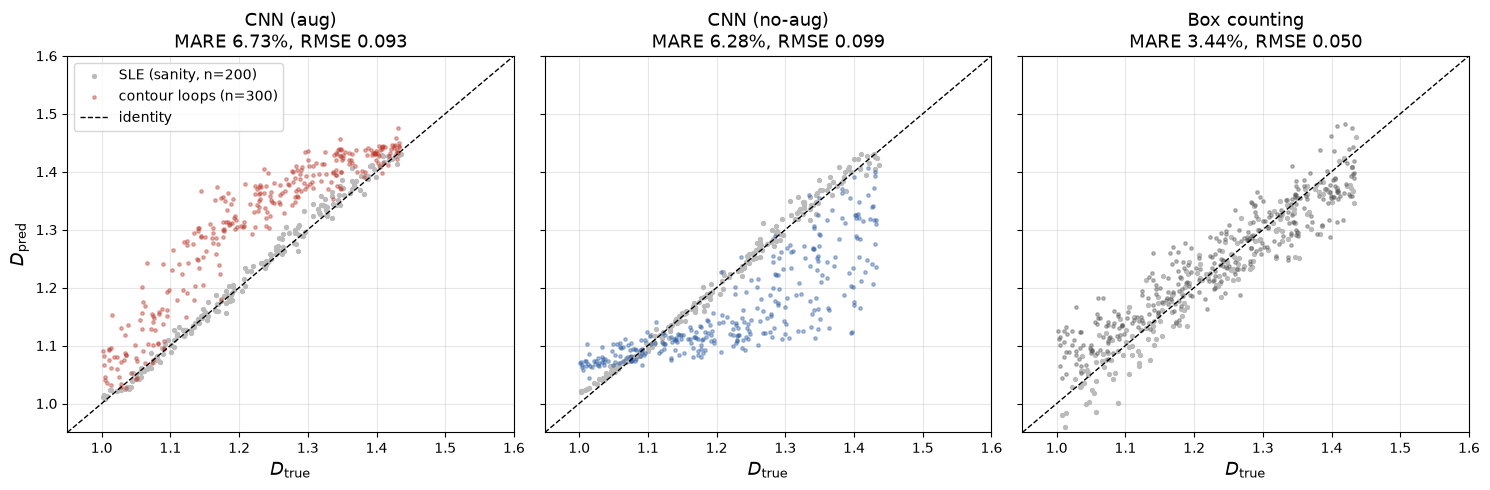

In [20]:
def savefig(fig, name):
    fig.savefig(RESULTS_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(RESULTS_DIR / f"{name}.pdf", bbox_inches="tight")
    if IMAGES_DIR.is_dir():
        fig.savefig(IMAGES_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

COLORS = {"D_cnn": "#c0392b", "D_cnn_noaug": "#2e5fa8", "D_box": "#555555"}   # red / blue / grey as in Result_*.ipynb

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
lim = (0.95, 1.6)
for ax, (c, name) in zip(axes, EST.items()):
    ax.scatter(sle["D_true"], sle[c], s=8, color="#bbbbbb", label=f"SLE (sanity, n={len(sle)})", zorder=1)
    ax.scatter(res["D_true"], res[c], s=6, alpha=0.4, color=COLORS[c], label=f"contour loops (n={len(res)})", zorder=2)
    ax.plot(lim, lim, "k--", lw=1, label="identity")
    m = cont_metrics.loc[name]
    ax.set_title(f"{name}\nMARE {m.MARE_pct:.2f}%, RMSE {m.RMSE_D:.3f}", fontsize=13)
    ax.set_xlabel(r"$D_{\rm true}$", fontsize=13)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.grid(True, alpha=0.3)
axes[0].set_ylabel(r"$D_{\rm pred}$", fontsize=13)
axes[0].legend(loc="upper left", fontsize=10)
fig.tight_layout()
savefig(fig, "contour_pred_vs_true")
plt.show()

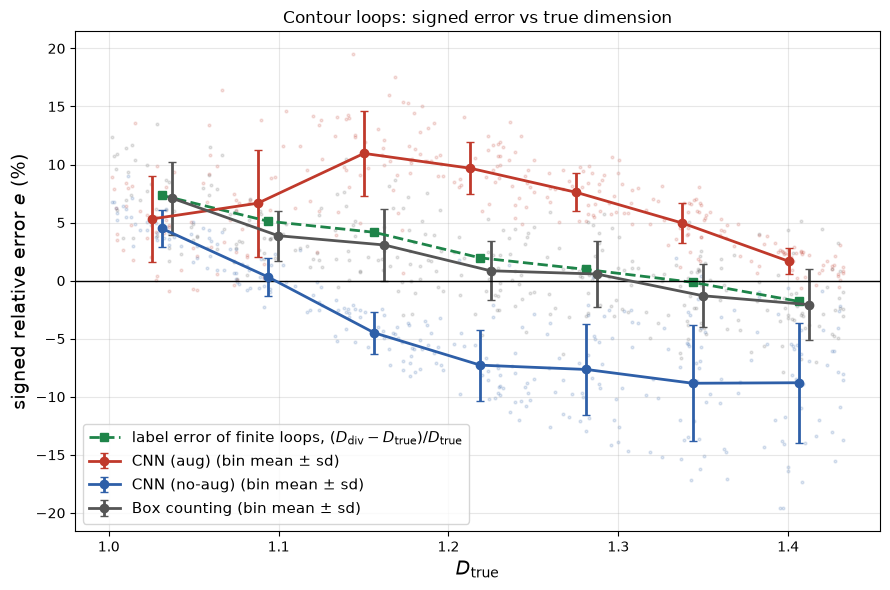

In [21]:
fig, ax = plt.subplots(figsize=(9, 6))
centers = 0.5 * (EDGES[1:] + EDGES[:-1])
for k, (c, name) in enumerate(EST.items()):
    e = rel_err(res[c], res["D_true"])
    ax.scatter(res["D_true"], e, s=4, alpha=0.15, color=COLORS[c])
    ax.errorbar(centers + (k - 1) * 0.006, cont_binned[(name, "mean_e_pct")],
                yerr=pd.Series(e).groupby(pd.cut(res["D_true"], EDGES, include_lowest=True), observed=False).std().values,
                fmt="o-", color=COLORS[c], lw=2, capsize=3, label=f"{name} (bin mean $\\pm$ sd)")
e_div = rel_err(res["D_div"], res["D_true"])
ax.plot(centers, pd.Series(e_div).groupby(pd.cut(res["D_true"], EDGES, include_lowest=True), observed=False).mean().values,
        "s--", color="#1e8449", lw=2, label=r"label error of finite loops, $(D_{\rm div}-D_{\rm true})/D_{\rm true}$")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel(r"$D_{\rm true}$", fontsize=14)
ax.set_ylabel(r"signed relative error $e$ (%)", fontsize=14)
ax.set_title("Contour loops: signed error vs true dimension")
ax.grid(True, alpha=0.3); ax.legend(fontsize=11)
fig.tight_layout()
savefig(fig, "contour_signed_error")
plt.show()

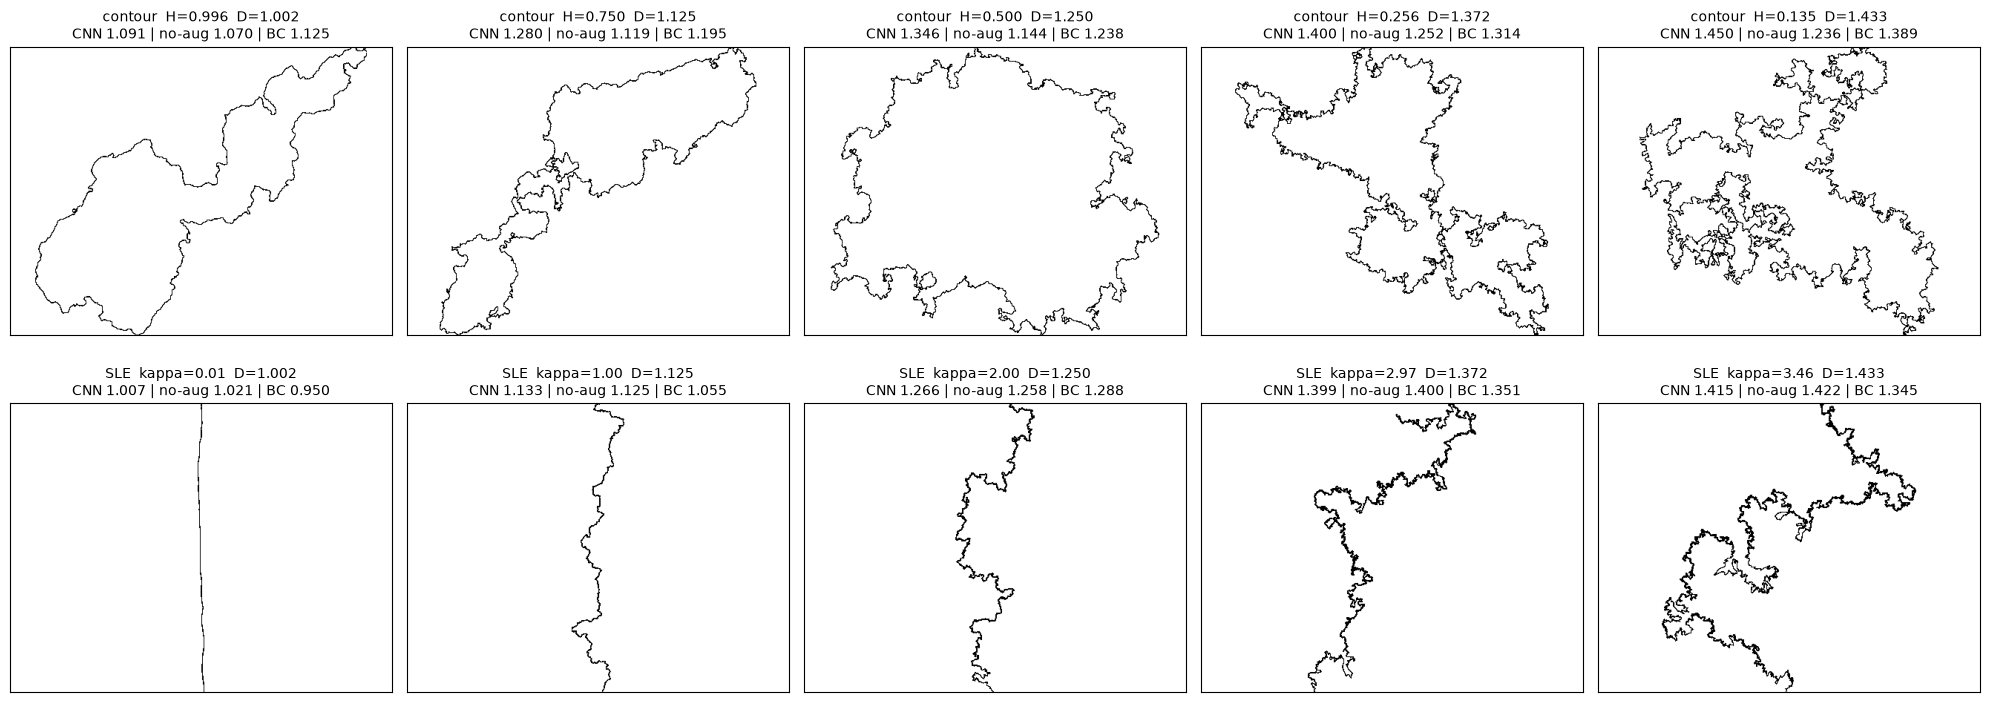

In [22]:
# example inputs: contour loops at a few H next to SLE curves at the matching D (kappa = 8 (D - 1)),
# shown exactly as the networks see them (binary 515 x 389 images)
H_SHOW = [1.0, 0.75, 0.5, 0.25, 0.125]
np.random.seed(SLE_SEED + 1)
fig, axes = plt.subplots(2, len(H_SHOW), figsize=(4 * len(H_SHOW), 7.6))
for j, Ht in enumerate(H_SHOW):
    i = int(np.argmin(np.abs(res["H"] - Ht)))
    r = res.iloc[i]
    axes[0, j].imshow(curve_to_image(CX[i], CY[i], closed=True), cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"contour  H={r.H:.3f}  D={r.D_true:.3f}\n"
                         f"CNN {r.D_cnn:.3f} | no-aug {r.D_cnn_noaug:.3f} | BC {r.D_box:.3f}", fontsize=10)
    xs, ys, Ds = sle_curve_fixed_kappa(8 * (r.D_true - 1))
    im = curve_to_image(xs, ys)
    Xs = to_cnn_input([im])
    axes[1, j].imshow(im, cmap="gray", vmin=0, vmax=1)
    axes[1, j].set_title(f"SLE  kappa={8 * (Ds - 1):.2f}  D={Ds:.3f}\n"
                         f"CNN {predict(model_aug, Xs)[0]:.3f} | no-aug {predict(model_noaug, Xs)[0]:.3f} | "
                         f"BC {fractal_dimension(im):.3f}", fontsize=10)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
savefig(fig, "contour_examples")
plt.show()

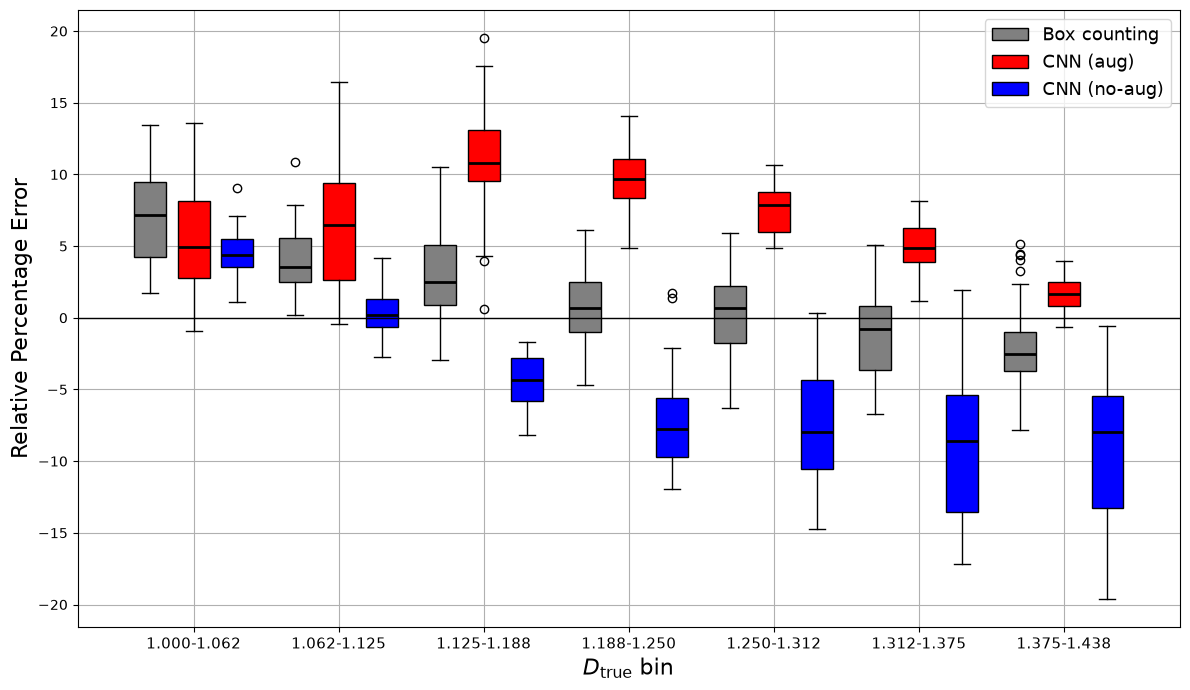

In [23]:
# boxplots of the signed error per D_true bin, same layout/colours as Results/Result_*.ipynb
fig, ax = plt.subplots(figsize=(12, 7))
b = pd.cut(res["D_true"], EDGES, include_lowest=True)
x = np.arange(1, len(EDGES))
for k, (c, col) in enumerate([("D_box", "grey"), ("D_cnn", "red"), ("D_cnn_noaug", "blue")]):
    e = pd.Series(rel_err(res[c], res["D_true"]))
    data_k = [e[(b == iv).values].values for iv in b.cat.categories]
    bp = ax.boxplot(data_k, positions=x + (k - 1) * 0.3, widths=0.22, patch_artist=True,
                    boxprops=dict(facecolor=col), medianprops=dict(color="black", linewidth=2))
    bp["boxes"][0].set_label(EST[c])
ax.axhline(0, color="k", lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"{lo:.3f}-{hi:.3f}" for lo, hi in zip(EDGES[:-1], EDGES[1:])], fontsize=11)
ax.set_xlabel(r"$D_{\rm true}$ bin", fontsize=16); ax.set_ylabel("Relative Percentage Error", fontsize=16)
ax.grid(True); ax.legend(fontsize=13)
fig.tight_layout()
savefig(fig, "contour_boxplot_binned")
plt.show()

## 8. Summary

The cell below prints the numbers quoted in the report (all derived from `results.csv` and `sle_sanity_results.csv`).

In [24]:
print(f"dataset: {npz_path.name}, n = {len(res)} contour loops; SLE sanity n = {len(sle)} (seed {SLE_SEED})\n")
print("SLE sanity (clean images):")
print(sle_metrics[["MARE_pct", "paper_MARE_pct", "median_e_pct", "IQR_e_pct", "RMSE_D", "bias_slope"]].round(4).to_string())
print("\nContour loops:")
print(cont_metrics[["MARE_pct", "median_e_pct", "IQR_e_pct", "RMSE_D", "bias_slope", "bias_slope_se"]].round(4).to_string())
print(f"\nconstant predictor MARE: {ref_mare:.2f} %")
print("\nContour loops, reference = divider estimate D_div:")
print(cont_metrics_div[["MARE_pct", "median_e_pct", "IQR_e_pct", "RMSE_D", "bias_slope"]].round(4).to_string())
print("\nWilcoxon (one-sided, |e| paired):")
print(wil.to_string())

dataset: contour_test_n300_seed12345.npz, n = 300 contour loops; SLE sanity n = 200 (seed 20261009)

SLE sanity (clean images):
              MARE_pct  paper_MARE_pct  median_e_pct  IQR_e_pct  RMSE_D  bias_slope
estimator                                                                          
CNN (aug)       0.8022             0.8        0.3047      1.297   0.013      0.0314
CNN (no-aug)    0.7488            0.75        0.2906      1.083  0.0122      0.0018
Box counting     2.357            2.49       -0.8137      3.425   0.036     -0.0542

Contour loops:
              MARE_pct  median_e_pct  IQR_e_pct  RMSE_D  bias_slope  bias_slope_se
estimator                                                                         
CNN (aug)        6.728         6.591      6.074  0.0934     -0.0853         0.0212
CNN (no-aug)     6.284        -5.046      8.034  0.0989     -0.4477         0.0223
Box counting     3.444         1.385      5.447    0.05      -0.255         0.0159

constant predictor M